In [36]:
import pandas as pd
import matplotlib.pyplot as plt
import math
import seaborn as sns

In [37]:
titanic_data = pd.read_csv("Titanic-Dataset.csv")
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [38]:
titanic_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [39]:
titanic_data.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [40]:
print(f"Total passengers: {len(titanic_data.index)}")

Total passengers: 891


<Axes: xlabel='Survived', ylabel='count'>

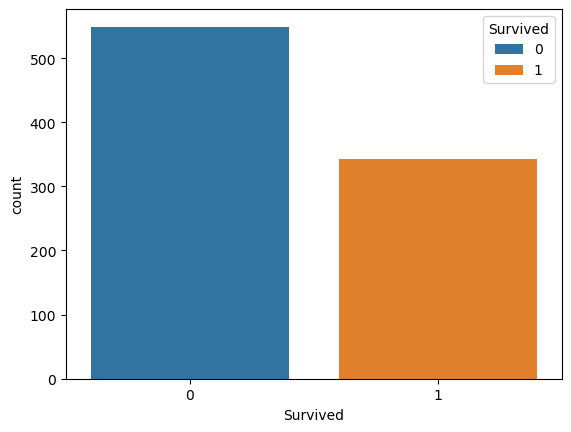

In [41]:
sns.countplot(
    x = "Survived",
    data= titanic_data,
    hue="Survived"
)

<Axes: xlabel='Sex', ylabel='count'>

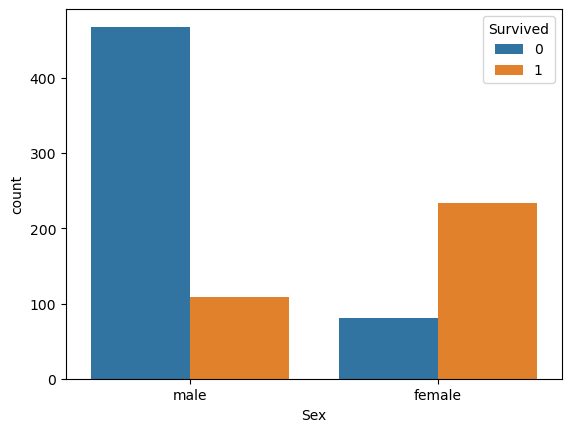

In [42]:
sns.countplot(
    x= "Sex",
    data= titanic_data,
    hue= "Survived"
)

<Axes: xlabel='Pclass', ylabel='count'>

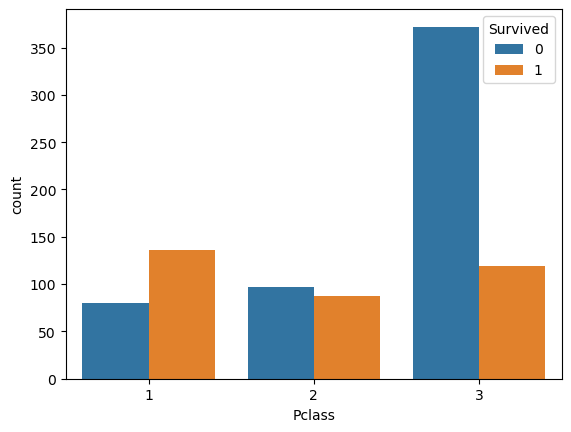

In [43]:
sns.countplot(
    x= "Pclass",
    data=titanic_data,
    hue="Survived"
)

In [44]:
titanic_data.drop("Cabin",axis=1, inplace=True)
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


<Axes: >

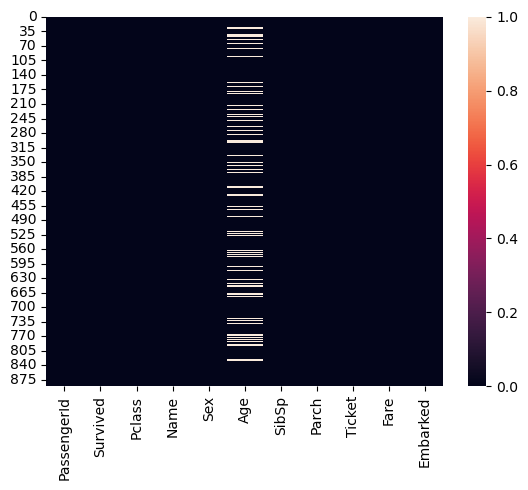

In [45]:
sns.heatmap(
    titanic_data.isnull()
)

In [46]:
titanic_data.dropna(inplace=True)

In [47]:
titanic_data.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [48]:
sex = pd.get_dummies(
    titanic_data["Sex"],
    drop_first=True
)

sex.head()

,male
0,True
1,False
2,False
3,False
4,True


In [49]:
embark = pd.get_dummies(
    titanic_data["Embarked"],
    drop_first=True
)
embark.head()

,Q,S
0,False,True
1,False,False
2,False,True
3,False,True
4,False,True


In [50]:
Pcl = pd.get_dummies(
    titanic_data["Pclass"],
    drop_first=True
)
Pcl.head()

,2,3
0,False,True
1,False,False
2,False,True
3,False,False
4,False,True


In [51]:
titanic_data = pd.concat([titanic_data, embark, Pcl, sex], axis=1)

In [52]:
titanic_data.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Q,S,2,3,male
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,False,True,False,True,True
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,False,False,False,False,False
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,False,True,False,True,False
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,False,True,False,False,False
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,False,True,False,True,True


In [53]:
titanic_data.drop(["Name","Ticket", "Fare", "Sex", "Embarked", "PassengerId", "Pclass"], axis=1, inplace= True)

In [54]:
titanic_data.head()

,Survived,Age,SibSp,Parch,Q,S,2,3,male
0,0,22.0,1,0,False,True,False,True,True
1,1,38.0,1,0,False,False,False,False,False
2,1,26.0,0,0,False,True,False,True,False
3,1,35.0,1,0,False,True,False,False,False
4,0,35.0,0,0,False,True,False,True,True


In [55]:
X = titanic_data.drop("Survived", axis=1)
y = titanic_data["Survived"]

In [56]:
X.head()

,Age,SibSp,Parch,Q,S,2,3,male
0,22.0,1,0,False,True,False,True,True
1,38.0,1,0,False,False,False,False,False
2,26.0,0,0,False,True,False,True,False
3,35.0,1,0,False,True,False,False,False
4,35.0,0,0,False,True,False,True,True


In [57]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [58]:
X.columns = X.columns.astype(str)

In [59]:
X.info()

<class 'pandas.core.frame.DataFrame'>
Index: 712 entries, 0 to 890
Data columns (total 8 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Age     712 non-null    float64
 1   SibSp   712 non-null    int64  
 2   Parch   712 non-null    int64  
 3   Q       712 non-null    bool   
 4   S       712 non-null    bool   
 5   2       712 non-null    bool   
 6   3       712 non-null    bool   
 7   male    712 non-null    bool   
dtypes: bool(5), float64(1), int64(2)
memory usage: 25.7 KB


In [60]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, 
    y,
    test_size= 0.3,
    random_state= 5
)

In [61]:
from sklearn.linear_model import LogisticRegression

logmodel = LogisticRegression(max_iter=1000)

In [62]:
logmodel = logmodel.fit(X_train, y_train)

In [63]:
predictions = logmodel.predict(X_test)

In [64]:
from sklearn.metrics import confusion_matrix

confusion_matrix(y_test, predictions)

array([[119,  17],
       [ 23,  55]])

In [65]:
from sklearn.metrics import accuracy_score

accuracy_score(y_test, predictions)*100

81.30841121495327

In [66]:
from sklearn.metrics import classification_report

classification_report(y_test, predictions)

'              precision    recall  f1-score   support\n\n           0       0.84      0.88      0.86       136\n           1       0.76      0.71      0.73        78\n\n    accuracy                           0.81       214\n   macro avg       0.80      0.79      0.79       214\nweighted avg       0.81      0.81      0.81       214\n'

In [67]:
X_test.head()

,Age,SibSp,Parch,Q,S,2,3,male
525,40.5,0,0,True,False,False,True,True
115,21.0,0,0,False,True,False,True,True
811,39.0,0,0,False,True,False,True,True
51,21.0,0,0,False,True,False,True,True
539,22.0,0,2,False,False,False,False,False


In [93]:
X.columns

Index(['Age', 'SibSp', 'Parch', 'Q', 'S', '2', '3', 'male'], dtype='object')

In [90]:
person = [[26, 0, 2, False, True, False, False, True]]

logmodel.predict(person)

c:\Users\Marvin\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1])